# 03 · Người dùng phàn nàn về điều gì? — Topic Modeling & Aspect Analysis

1. **Khám phá** (unsupervised): NMF trên TF-IDF của review tiêu cực để tìm các chủ đề phàn nàn chính.
2. **Đo lường** (rule-based): chuyển các chủ đề thành bộ từ khoá khía cạnh (`src/momo_reviews/aspects.py`) — minh bạch, ổn định, theo dõi được theo thời gian.
3. **Ưu tiên hoá**: khía cạnh nào vừa *nhiều người nhắc* vừa *tiêu cực nhất* → đề xuất hành động.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display, Markdown

from momo_reviews.config import CLEAN_FILE
from momo_reviews.viz import set_style, save, SENTIMENT_COLORS, BLUE, INK_2
set_style()
pd.set_option("display.max_colwidth", 160)

df = pd.read_parquet(CLEAN_FILE)
print(f"{len(df):,} review | {df['at'].min():%d/%m/%Y} → {df['at'].max():%d/%m/%Y}")
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer
from momo_reviews.aspects import aspect_matrix, ASPECTS

STOP = ["và", "là", "thì", "mà", "có", "của", "cho", "này", "đã", "được", "bị", "với", "các", "những", "một",
        "rồi", "lại", "cũng", "nữa", "khi", "để", "nên", "vì", "như", "ra", "vào", "lên", "đi", "làm", "rất",
        "quá", "nhưng", "hay", "thế", "gì", "vậy", "không", "tôi", "mình", "em", "anh", "chị", "bạn", "momo",
        "ứng", "dụng", "ứng dụng", "num", "neg_emoji", "pos_emoji", "nó", "ai", "sao", "nào", "luôn", "còn",
        "mới", "mãi", "thôi", "đâu", "ạ", "nha", "nhé", "ơi", "ko", "trong", "từ", "đến", "tại", "sẽ", "đang"]

217,336 review | 28/05/2014 → 22/10/2026


## 1. Topic modeling (NMF) trên review tiêu cực

In [2]:
neg = df[(df["sentiment"] == "negative") & (df["n_words"] >= 4) & (~df["is_spam"])]
neg = neg[neg["at"] >= neg["at"].max() - pd.DateOffset(years=3)]   # 3 năm gần nhất = vấn đề còn "sống"
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=10, max_df=0.5, stop_words=STOP, max_features=30_000)
X = vec.fit_transform(neg["text_clean"])
K = 10
nmf = NMF(n_components=K, random_state=42, init="nndsvd", max_iter=400)
W = nmf.fit_transform(X)
terms = vec.get_feature_names_out()
topics = pd.DataFrame({f"Topic {k+1}": [terms[i] for i in nmf.components_[k].argsort()[::-1][:10]] for k in range(K)}).T
topics["share"] = pd.Series(W.argmax(1)).value_counts(normalize=True).sort_index().values
print(f"{len(neg):,} review tiêu cực (3 năm gần nhất)")
topics.sort_values("share", ascending=False).style.format({"share": "{:.1%}"})

19,280 review tiêu cực (3 năm gần nhất)


,0,1,2,3,4,5,6,7,8,9,share
Topic 5,tiền,chuyển,chuyển tiền,trừ,trừ tiền,nạp,nhận,mất,nạp tiền,rút,25.1%
Topic 10,trả,sau,ví,trả sau,ví trả,phí,lừa,dùng,đảo,lừa đảo,14.0%
Topic 8,lỗi,tục,liên tục,lỗi liên,hoài,liên,lỗi hoài,toàn,báo lỗi,toàn lỗi,9.8%
Topic 6,khách,khách hàng,chăm,sóc,chăm sóc,hàng,sóc khách,trợ,tệ,hỗ,9.0%
Topic 4,toán,thanh,thanh toán,tự,động,tự động,động thanh,trừ,tự thanh,trừ tiền,8.8%
Topic 7,xác,xác thực,thực,mặt,khuôn,khuôn mặt,thực khuôn,sinh,trắc,học,7.5%
Topic 9,càng,ngày càng,ngày,càng ngày,tệ,lag,càng tệ,càng lag,chậm,càng chậm,7.3%
Topic 2,nhập,đăng,đăng nhập,lỗi đăng,mã,thoại,điện thoại,điện,otp,số,6.5%
Topic 1,ngân,ngân hàng,liên kết,kết,liên,hàng,tài,tài khoản,khoản,kết ngân,6.3%
Topic 3,cập,nhật,cập nhật,nhật xong,bắt cập,xong,bắt,nhật hoài,bản,hoài,5.7%


In [3]:
for k in topics.sort_values("share", ascending=False).index[:5]:
    i = int(k.split()[1]) - 1
    ex = neg.iloc[W[:, i].argsort()[::-1][:3]]["content"].str.slice(0, 160).tolist()
    display(Markdown(f"**{k}** — " + ", ".join(topics.loc[k, range(5)]) + "\n\n" + "\n".join(f"> {e}" for e in ex)))

**Topic 5** — tiền, chuyển, chuyển tiền, trừ, trừ tiền

> K chuyển tiền được
> Chuyển tiền không được :))
> momo không chuyển tiền được

**Topic 10** — trả, sau, ví, trả sau, ví trả

> Ví trả sau như c
> Ví trả sau tệ
> Ví trả sau như cc

**Topic 8** — lỗi, tục, liên tục, lỗi liên, hoài

> momo bị lỗi à
> momo ơi sao app gì lỗi thế
> loi login app như l

**Topic 6** — khách, khách hàng, chăm, sóc, chăm sóc

> cskh có như không
> Chăm sóc khách hàng như c
> Có cskh k thế

**Topic 4** — toán, thanh, thanh toán, tự, động

> thanh toán không được
> momo bị sao thế ko thanh toán đc ?
> app bị j r không thanh toán đc

Các topic NMF hội tụ về những nhóm vấn đề rõ ràng (đăng nhập/OTP, xác thực danh tính, chuyển–nạp–rút tiền, lỗi/chậm, CSKH, mất tiền…). Dựa trên đó, bộ từ khoá khía cạnh trong `aspects.py` được xây dựng để **đo lường nhất quán** qua các năm.

## 2. Phủ của bộ khía cạnh

In [4]:
A = aspect_matrix(df["text_clean"])
df_a = pd.concat([df[["at", "score", "sentiment", "n_words", "is_spam", "version"]], A], axis=1)
df_a = df_a[(df_a["n_words"] >= 3) & (~df_a["is_spam"])]
cov = (df_a[list(ASPECTS)].sum(1) > 0).groupby(df_a["sentiment"]).mean()
display(Markdown("**Tỷ lệ review (≥3 từ) được gắn ít nhất 1 khía cạnh:** " +
                 ", ".join(f"{k}: {v:.0%}" for k, v in cov.items())))

**Tỷ lệ review (≥3 từ) được gắn ít nhất 1 khía cạnh:** negative: 73%, neutral: 68%, positive: 41%

## 3. Ma trận ưu tiên: khía cạnh nào cần xử lý trước?

In [5]:
recent = df_a[df_a["at"] >= df_a["at"].max() - pd.DateOffset(months=12)]
stats = pd.DataFrame({
    "so_review": recent[list(ASPECTS)].sum(),
    "ty_le_nhac_den": recent[list(ASPECTS)].mean(),
    "ty_le_tieu_cuc": [(recent.loc[recent[a] == 1, "sentiment"] == "negative").mean() for a in ASPECTS],
    "rating_tb": [recent.loc[recent[a] == 1, "score"].mean() for a in ASPECTS],
}, index=list(ASPECTS)).sort_values("so_review", ascending=False)
base_neg = (recent["sentiment"] == "negative").mean()
stats.style.format({"so_review": "{:,}", "ty_le_nhac_den": "{:.1%}", "ty_le_tieu_cuc": "{:.0%}", "rating_tb": "{:.2f}"}) \
     .background_gradient(subset=["ty_le_tieu_cuc"], cmap="Reds")

,so_review,ty_le_nhac_den,ty_le_tieu_cuc,rating_tb
Lỗi & hiệu năng,"1,639",22.4%,82%,1.60
Mất tiền & hoàn tiền,943,12.9%,95%,1.19
Chăm sóc khách hàng,823,11.3%,93%,1.26
Nạp/Rút & ngân hàng,787,10.8%,88%,1.47
Chuyển & nhận tiền,772,10.6%,82%,1.67
Giao diện & quảng cáo,501,6.9%,37%,3.47
Đăng nhập & OTP,401,5.5%,84%,1.56
Phí dịch vụ,376,5.1%,92%,1.30
Vay & trả sau,365,5.0%,90%,1.35
eKYC & định danh,264,3.6%,90%,1.36


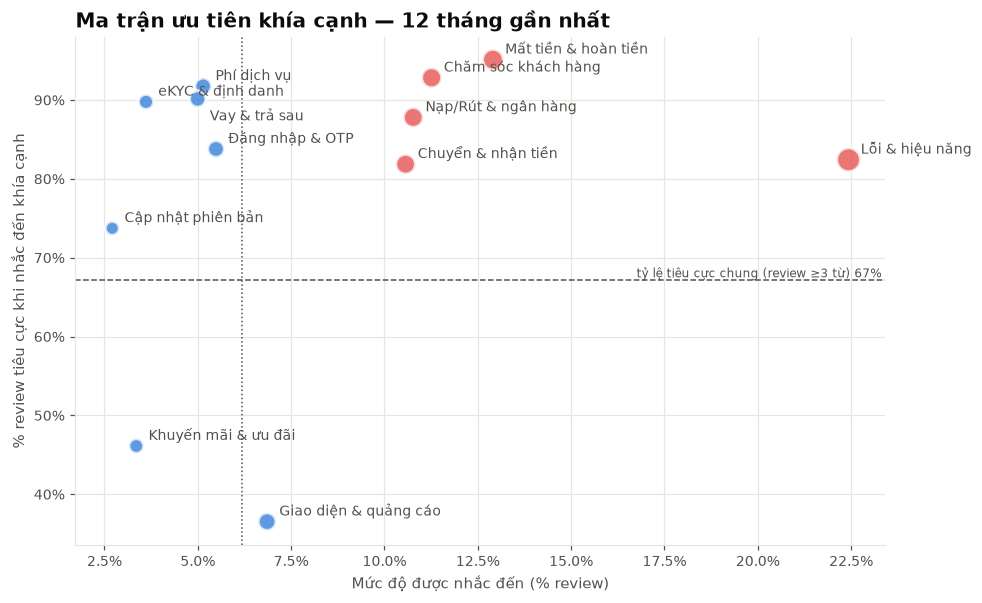

**Góc phải-trên (đỏ) = ưu tiên cao:** Lỗi & hiệu năng, Mất tiền & hoàn tiền, Chăm sóc khách hàng, Nạp/Rút & ngân hàng, Chuyển & nhận tiền

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 6))
x, y = stats["ty_le_nhac_den"], stats["ty_le_tieu_cuc"]
hot = (y > base_neg) & (x > x.median())
ax.scatter(x, y, s=np.sqrt(stats["so_review"]) * 6, c=np.where(hot, SENTIMENT_COLORS["negative"], BLUE),
           alpha=0.75, edgecolor="white", linewidth=2)
# Đặt nhãn tránh chồng chữ: thử lần lượt các vị trí, bỏ vị trí trùng với nhãn đã đặt
fig.canvas.draw(); placed = []
for name, xi, yi in sorted(zip(stats.index, x, y), key=lambda t: -t[2]):
    px, py = ax.transData.transform((xi, yi))
    for dx, dy in [(8, 4), (8, -14), (-8, 4), (-8, -14), (8, 16)]:
        w = 6.5 * len(name)
        box = (px + dx - (w if dx < 0 else 0), py + dy, w, 12)
        if not any(abs(box[0] - b[0]) < (w + b[2]) / 2 + 4 and abs(box[1] - b[1]) < 13 for b in placed):
            break
    placed.append(box)
    ax.annotate(name, (xi, yi), xytext=(dx, dy), textcoords="offset points", fontsize=9, color=INK_2,
                ha="right" if dx < 0 else "left")
ax.axhline(base_neg, color=INK_2, linestyle="--", linewidth=1)
ax.axvline(x.median(), color=INK_2, linestyle=":", linewidth=1)
ax.text(ax.get_xlim()[1], base_neg, f"tỷ lệ tiêu cực chung (review ≥3 từ) {base_neg:.0%} ", ha="right", va="bottom", fontsize=8, color=INK_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("Mức độ được nhắc đến (% review)"); ax.set_ylabel("% review tiêu cực khi nhắc đến khía cạnh")
ax.set_title("Ma trận ưu tiên khía cạnh — 12 tháng gần nhất")
save(fig, "03_aspect_priority_matrix"); plt.show()
display(Markdown("**Góc phải-trên (đỏ) = ưu tiên cao:** " + ", ".join(stats.index[hot])))

## 4. Xu hướng các khía cạnh tiêu cực theo thời gian

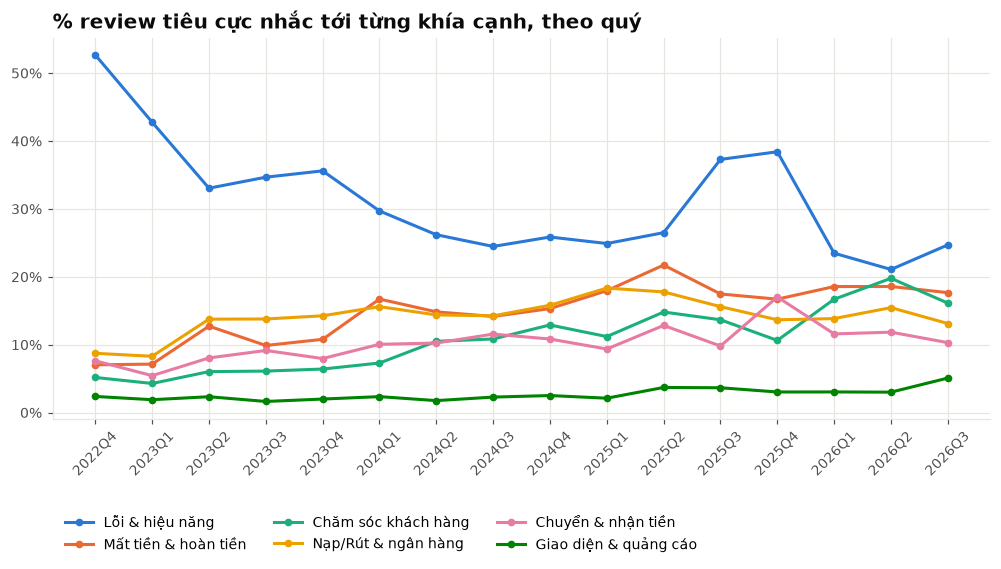

In [7]:
neg_a = df_a[(df_a["sentiment"] == "negative") & (df_a["at"] >= df_a["at"].max() - pd.DateOffset(years=4))]
trend = neg_a.groupby(neg_a["at"].dt.to_period("Q"))[list(ASPECTS)].mean()
trend = trend.iloc[:-1] if len(trend) > 1 else trend   # bỏ quý chưa kết thúc
top = stats.index[:6]
fig, ax = plt.subplots(figsize=(11, 4.5))
for a in top:
    ax.plot(trend.index.astype(str), trend[a], marker="o", markersize=4, label=a)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.tick_params(axis="x", rotation=45)
ax.set_title("% review tiêu cực nhắc tới từng khía cạnh, theo quý")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.22))
save(fig, "03_aspect_trend"); plt.show()

In [8]:
change = (trend.iloc[-2:].mean() - trend.iloc[-6:-2].mean()).sort_values(ascending=False)
display(Markdown("**Thay đổi tỷ trọng (2 quý gần nhất so với 4 quý trước đó), điểm %:**"))
(change * 100).round(1).to_frame("Δ điểm %")

**Thay đổi tỷ trọng (2 quý gần nhất so với 4 quý trước đó), điểm %:**

,Δ điểm %
Chăm sóc khách hàng,4.0
eKYC & định danh,3.4
Phí dịch vụ,1.8
Vay & trả sau,0.7
Giao diện & quảng cáo,0.7
Khuyến mãi & ưu đãi,0.3
Đăng nhập & OTP,-0.3
Mất tiền & hoàn tiền,-0.5
Nạp/Rút & ngân hàng,-0.9
Cập nhật phiên bản,-1.1


## 5. Đề xuất hành động (dựa trên dữ liệu)

| Phát hiện | Đề xuất | KPI theo dõi |
|---|---|---|
| Các khía cạnh ở góc đỏ của ma trận ưu tiên | Đưa vào backlog ưu tiên; gắn owner theo từng khía cạnh | % review tiêu cực nhắc tới khía cạnh, theo release |
| Tỷ lệ tiêu cực tăng đột biến theo phiên bản (notebook 01) | Thêm cảnh báo tự động sau mỗi release (z-score theo ngày) | Thời gian phát hiện sự cố |
| Review 4–5★ có nội dung phàn nàn (notebook 02) | Dùng mô hình sentiment gắn cờ để CSKH xử lý | % review được xử lý trong 24h |
| Review tiêu cực được trả lời ít hơn / chậm | Ưu tiên trả lời review tiêu cực có nhiều 👍 | Tỷ lệ trả lời & thời gian phản hồi |

*Giới hạn:* bộ từ khoá không bắt được mọi cách diễn đạt; review trên Store là mẫu thiên lệch (người rất vui/rất bực viết nhiều hơn) — không đại diện cho toàn bộ người dùng.